# M03 — Magnetic survey admission and spatial holdout

**Question:** How does a spatially blocked M03 plan prevent geometry leakage while leaving magnetic corrections and inversion unresolved?

**Level 2 · Prerequisites: foundations notebook; read time: 25 minutes.**



## Objectives

Execute the strict product parser and geometry planner on the committed authored 288-row protocol fixture. It has no measured magnetic response. This is a partition/leakage-control example, not corrections, gridding, continuation or inversion.


## Setup

Use the already reviewed Python 3.12 pipeline environment. This notebook installs nothing.
Import repository code and confirm its source file.

In [1]:
import runpy, sys
from pathlib import Path

root = Path.cwd().parents[2]
sys.path.insert(0, str(root / "data-pipeline"))
from magnetic_survey_json import parse_request
from magnetic_survey import plan_geometry

support = runpy.run_path(str(root / "tests/data/magnetic_survey_support.py"))
# Verify the actual planner's source location.
print(Path(__import__("magnetic_survey").__file__).name)


magnetic_survey.py


## Data

Execute the strict product parser and geometry planner on the committed authored 288-row protocol fixture. It has no measured magnetic response. This is a partition/leakage-control example, not corrections, gridding, continuation or inversion.

**Files:** tests/data/magnetic_survey_support.py, tests/fixtures/magnetic_survey/generate.py, docs/methods/magnetic-survey/README.md


## Method

The contract fixes ENU metres, source/flight grouping, deterministic spatial blocks, an outer holdout and buffered folds. Rows sharing group or block stay together; rank and coverage are checked before likelihood materialization. This controls spatial leakage but does not correct diurnal variation, IGRF, altitude or provider grids.

The fixture provides east/north/up coordinates in metres, flight-group IDs, an explicit spatial block width and a 200 m buffer. The planner unions rows sharing either a flight group or a spatial block; transitive connections form indivisible units. It deterministically orders those units, holds out roughly one fifth for outer evaluation, then creates development folds. For each fold, fit rows within distance b of a validation or outer row are removed: retain i only if minⱼ∈H ‖xᵢ−xⱼ‖₂>b. This is a leakage-control rule, not a magnetic correction. Verde’s spatial train/test splitting is the related reference [API](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html).

The planner also checks geometric rank: for centered horizontal coordinates X=[1,e−ē,n−n̄], rank(X)=3 is required so the split is not collapsed to a line. This checks coordinate support, not field-property identifiability. The fixture has twelve flight lines and 288 positions but zero magnetic response. The figure shows exact row membership from fold 1, including buffered exclusions. Current eligibility explicitly withholds online/full-method acceptance because licensing, lineage, a validated likelihood and optimizer binding are unresolved.

Execute the product method on the declared control.

In [2]:
raw = support["encode"](support["request"]())
# Validate exact serialized bytes and compute the deterministic geometry seal.
handle = parse_request(raw)
plan = plan_geometry(handle)
print(
    {
        "schema": handle.metadata()["schema"],
        "partition_sha256": plan["partition"]["sha256"],
        "outer_rows": len(plan["partition"]["outer_rows"]["data"]),
        "folds": len(plan["partition"]["folds"]),
        "inverse_run": False,
    }
)


{'schema': 'magnetic-survey-inversion-1', 'partition_sha256': '18c36c658217ee39da1c3cdda336389f4b0a0d8115c928b6707a114e1753e12e', 'outer_rows': 72, 'folds': 3, 'inverse_run': False}


Blocked spatial splitting is preferable to random point splits for correlated flight lines. Verde documents spatial train/test splitting ([API reference](https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html)); this product additionally seals group membership and buffers held-out rows. Current modules run only parser and geometry logic: no magnetic correction, kernel or optimizer.
Use the planner’s returned row indices directly. The chart is a map of the partition design, with physical coordinate axes in metres; its categories encode fit/holdout policy, never magnetic amplitude.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Plot exact product-planner indices on the fixture's authored local geometry; colors denote partition role only.
meta = handle.metadata()
xyz = np.asarray(meta["geometry"]["receivers_m"]["data"], dtype=float).reshape(-1, 3)
outer = np.asarray(plan["partition"]["outer_rows"]["data"], dtype=int)
f = plan["partition"]["folds"][0]
fit = np.asarray(f["fit_rows"]["data"], dtype=int)
validation = np.asarray(f["validation_rows"]["data"], dtype=int)
buffered = np.asarray(f["buffered_rows"]["data"], dtype=int)
dev = set(plan["partition"]["development_rows"]["data"])
assert not (set(outer) & dev) and not (
    set(fit) & set(validation) or set(fit) & set(buffered) or set(validation) & set(buffered)
)


### Render the spatial split

The partition arrays have already been checked for overlap and leakage. This figure locates each actual planner row on the survey geometry; it does not imply that a magnetic response was measured or modeled.

{'outer': 72, 'fold_fit': 144, 'fold_validation': 72, 'buffered': 0, 'full_method_accepted': False, 'field_source_verified': False, 'geology_truth_known': False, 'online_admitted': False}


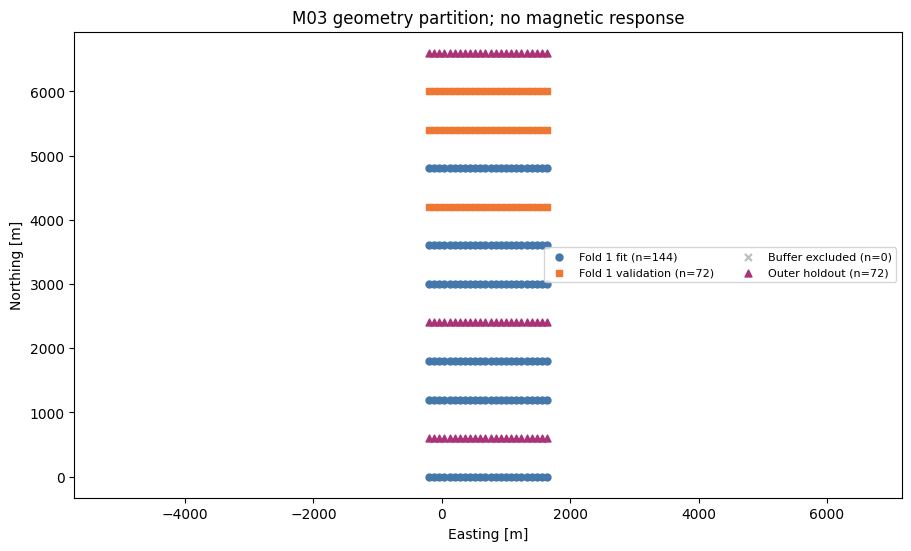

In [4]:
# Render the spatial split.
fig, ax = plt.subplots(figsize=(9, 5.4), constrained_layout=True)
for ids, label, color, marker in [
    (fit, "Fold 1 fit", "#4477aa", "o"),
    (validation, "Fold 1 validation", "#ee7733", "s"),
    (buffered, "Buffer excluded", "#bbbbbb", "x"),
    (outer, "Outer holdout", "#aa3377", "^"),
]:
    ax.scatter(xyz[ids, 0], xyz[ids, 1], label=f"{label} (n={len(ids)})", c=color, marker=marker, s=25)
ax.set(xlabel="Easting [m]", ylabel="Northing [m]", title="M03 geometry partition; no magnetic response")
ax.set_aspect("equal", adjustable="datalim")
ax.legend(ncol=2, fontsize=8)
print(
    {
        "outer": len(outer),
        "fold_fit": len(fit),
        "fold_validation": len(validation),
        "buffered": len(buffered),
        **plan["claims"],
    }
)
plt.show()


### Visual check of the encoded receiver geometry

This map shows the fixture’s receiver coordinates and labeled protocol groups before the planner is interpreted. It can reveal coordinate ordering or a misplaced block, but every response value is zero by construction. The view therefore supports a geometry and serialization check only; it cannot show magnetic anomalies, survey coverage quality, or predictive separation.


In [5]:
# Reparse the exact same request bytes as a separate step.
handle_repeat = parse_request(raw)
print(handle_repeat.metadata()["observations"]["values_sha256"])


71c642b31e5890a15ef92f3cbeba34edfb6e2e9f63079ecbda13a89d426f7d8b


Recompute the sealed geometry plan and check determinism.

In [6]:
# Recompute the sealed geometry plan and check determinism.
plan_repeat = plan_geometry(handle_repeat)
print(plan_repeat["partition"]["sha256"] == plan["partition"]["sha256"])


True


Hash the canonical partition identity returned by the pipeline.

In [7]:
# Hash the canonical partition identity returned by the pipeline.
from magnetic_survey_json import digest

print(digest(plan["partition"]))


e9393ca2a06106e09bc26583f7d26d23c784788df0beecf3da3e34da1b61883e


A malformed request is a negative control, not a smaller fallback survey.

In [8]:
# A malformed request is a negative control, not a smaller fallback survey.
from magnetic_survey_json import InputError

try:
    parse_request(raw + b"x")
except InputError as error:
    print("refused:", error.code)


refused: type


The first map displays the planner-selected row roles at their actual east/north coordinates. This companion chart aggregates the same sealed fold records into counts, so it exposes how the outer holdout, fold validation and buffer exclusions reduce the usable training sample. Counts describe split geometry only; no magnetic response exists in this fixture, so they are not prediction skill or survey coverage.

Compare retained training, validation and buffered row counts across the planned folds.

{'Fold 1': {'fit': 144, 'validation': 72, 'buffered': 0}, 'Fold 2': {'fit': 144, 'validation': 72, 'buffered': 0}, 'Fold 3': {'fit': 144, 'validation': 72, 'buffered': 0}}


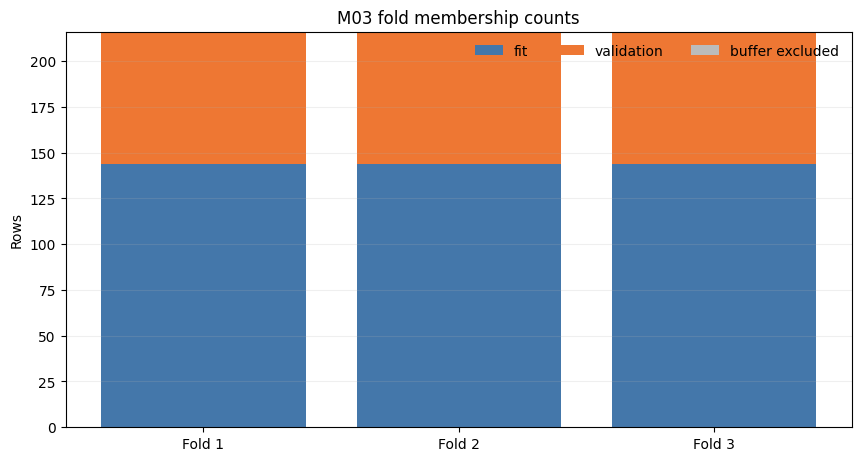

In [9]:
# Aggregate exact planner indices for each predeclared fold.
import numpy as np
import matplotlib.pyplot as plt

folds = plan["partition"]["folds"]
labels = [f"Fold {i + 1}" for i in range(len(folds))]
fit_n = [len(f["fit_rows"]["data"]) for f in folds]
validation_n = [len(f["validation_rows"]["data"]) for f in folds]
buffer_n = [len(f["buffered_rows"]["data"]) for f in folds]
x = np.arange(len(folds))
fig, ax = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
ax.bar(x, fit_n, label="fit", color="#4477aa")
ax.bar(x, validation_n, bottom=fit_n, label="validation", color="#ee7733")
bottom = np.asarray(fit_n) + np.asarray(validation_n)
ax.bar(x, buffer_n, bottom=bottom, label="buffer excluded", color="#bbbbbb")
ax.set(xticks=x, xticklabels=labels, ylabel="Rows", title="M03 fold membership counts")
ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.2)
print(
    {label: {"fit": a, "validation": b, "buffered": c} for label, a, b, c in zip(labels, fit_n, validation_n, buffer_n)}
)
plt.show()


These bars are direct counts from the planner’s serialized row indices, not a second split implementation. A large buffer can sharply reduce training rows, while validation counts remain fixed by the sealed fold; this trade-off is visible before any response or inverse is considered. The outer holdout is not included in these development-fold categories. The chart therefore helps audit whether the declared geometry design leaves enough development support, but cannot establish that a future magnetic estimator will generalize.

## Results

A successful run means schema and partition checks passed, not M03 processing, held-out prediction or field acceptance. On failure, retain the refusal; do not shrink buffers or synthesize measurements.


The geometry planner creates indivisible units by joining shared flight groups and spatial blocks, then seals an outer holdout and buffered folds. Since it plans from metadata, its deterministic output cannot be read as a prediction score. Spatially adjacent measurements can share broad potential-field structure, so a random point split would overstate independence. Blocking addresses that specific leakage pathway but leaves line-correlated errors and acquisition systematics untouched. The fixture’s row count and partition digest are computed evidence about the declared test object, not about a real flight survey. A later inversion would need corrected observations, uncertainty, a source-verified kernel and
independent predictions before geological claims could be evaluated.

**Answer:** The fresh plan places 72 of 288 protocol rows in the outer holdout. Each of three folds contains 144 fit rows and 72 validation rows, with zero buffered rows; `inverse_run` is false. This is evidence for partition construction, not a magnetic prediction.

The planner groups correlated flight-line and spatial-block rows, seals a 72-row outer holdout, and checks fold overlap. It reads geometry and source metadata only; zero-valued response means it cannot evaluate magnetic corrections, gridding or predictive accuracy.


## Summary

Spatial grouping and the 72-row outer holdout are computed successfully, but the protocol contains no measured magnetic response. The planner therefore demonstrates leakage control only; M03 corrections, line levelling, gridding and held-out prediction remain untested.





## References

- https://www.fatiando.org/verde/latest/api/generated/verde.train_test_split.html